# Hesak – Step 16: v11 (after test round 4)

**Why (RS, 9–10 Nov, log section 8):** round 4 (v10, run once) reached 2 of 4 targets (log 6.20). That result stays as it is.
v11 changes, all decided by RS **after** round 4 (so round 4 cannot measure v11; the honest number comes from **round 5**):

1. **alarm = fire alarm / smoke detector ONLY.** The Saudi phone alert and Saudi street alarm are out. 23 clips were MOVED (not deleted)
   to `data/alarm_excluded`: `train_extra/alarm` t30–t49, `alarm_LM_01_yt`, `alarm_LM_r2_03` / `04`. Each file's Drive description says where it came from.
2. **phone_tone is removed** from what the user sees (16 sounds). It stays inside the head (it helps the head tell phones from bells / alarms).
3. **birds = YAMNet alone at its labels threshold 0.475** (not re-tuned; v6b had raised it to 0.925 on 4 clips).
4. **rain / storm must also fire for rain WITHOUT thunder:** `train_extra/rain` = COPIES of the 5 round-4 rain clips (round 4 already ran once)
   + new rain-only clips from RS. Training only.
5. washing machine: postponed (no change).

**Same as v10:** head design, FSD50K data, round-2 + extra clips in training (x3), round-3 clips for tuning only, short-sound rule option for scream,
tier allowances, false alarms on `other` <= 20%.

**The check (Cell 18):** v6b, **v10a** (round-4 model) and **v11a** (new model), all tuned on the OLD tuning set only, compared on the round-3 clips
(fair between them, not a new test). Final v11 (Cell 19) is tuned on old set + round 3 (optimistic).

**Not changed:** YAMNet, labels files (v1.9 / v2.0), NFR, the v6b–v10 files, and the round-4 result.

**How to run:** T4 GPU, Run all (≈ 15–30 min; FSD50K clips are cached). `data/test_round5` must be empty or missing.
Wait until the LAST cell prints `Saved: ...`, then send the downloaded `.ipynb`.
**Outputs (`outputs/`):** `hesak_head_v11.keras`, `hesak_head_v11_config.json`, `step5v11_*.csv`, `step5v11_training_curves.png`.

In [ ]:
# ---------------------------------------------------------------
# Cell 1: Library versions (the report's technology table needs them) and GPU check
# ---------------------------------------------------------------
import sys, platform, importlib
print('Python', sys.version.split()[0], '|', platform.platform())
for name in ['numpy', 'pandas', 'librosa', 'soundfile', 'tensorflow', 'tensorflow_hub', 'keras', 'huggingface_hub', 'sklearn']:
    try:
        module = importlib.import_module(name)          # import by name so a missing library does not crash the cell
        print(f'{name:16s}', getattr(module, '__version__', '?'))
    except Exception as e:
        print(f'{name:16s} NOT INSTALLED', e)
import tensorflow as tf
print('GPU:', tf.config.list_physical_devices('GPU') or 'NONE (it still works, only slower)')

Python 3.13.16 | Linux-6.6.159+-x86_64-with-glibc2.39
numpy            2.4.6
pandas           2.2.3
librosa          0.11.0
soundfile        0.14.0
tensorflow       2.21.0


/usr/local/lib/python3.13/dist-packages/tensorflow_hub/__init__.py:61: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import parse_version


tensorflow_hub   0.16.1
keras            3.13.2
huggingface_hub  1.33.0
sklearn          1.6.1
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [ ]:
# ---------------------------------------------------------------
# Cell 2: Drive, paths, labels (v2.0 output layer on top of the internal v1.9), fixed random seed
#   No labels file is changed in this notebook. v11 output layer = v2.0 WITHOUT phone_tone (RS, 10 Nov): 16 sounds.
# ---------------------------------------------------------------
from google.colab import drive
import os, json, re, random, warnings, shutil
import numpy as np, pandas as pd
warnings.filterwarnings('ignore')                       # librosa prints many harmless format warnings

drive.mount('/content/drive')                           # choose the team Google account (email removed for the public repo)

BASE  = '/content/drive/MyDrive/Colab Notebooks/Hesak_YAMNet'
REC   = f'{BASE}/data/hesak_recordings'
TEST_FINAL = f'{BASE}/data/test_final'                   # round-1 test clips: TUNING set since v5
R2_DIR = f'{BASE}/data/test_round2'                      # round-2 clips: TRAINING from v7
R3_DIR = f'{BASE}/data/test_round3'                      # round-3 clips: TUNING from v7
OUT   = f'{BASE}/outputs'
CACHE_OURS = f'{OUT}/cache_yamnet'                       # YAMNet outputs of our files from steps 2 / 2c
CACHE_TRAIN = f'{OUT}/cache_train'                       # our files cached during training (washing_machine windows)
CACHE_FSD = f'{OUT}/cache_fsd50k'                        # YAMNet outputs of FSD50K clips
CACHE_TF = f'{OUT}/cache_test_final'                     # YAMNet outputs of test_final clips (step 6)
CACHE_R2 = f'{OUT}/cache_test_round2'                    # YAMNet outputs of round-2 clips (step 7)
CACHE_R3 = f'{OUT}/cache_test_round3'                    # YAMNet outputs of round-3 clips (step 9)
EXTRA_DIR = f'{BASE}/data/train_extra'                   # extra TRAINING clips (scream, alarm, rain), RS 8-10 Nov (v11: alarm = fire alarm only)
CACHE_EXTRA = f'{OUT}/cache_train_extra'                 # YAMNet outputs of the extra clips
for d in [CACHE_TRAIN, CACHE_FSD, CACHE_TF, CACHE_R2, CACHE_R3, CACHE_EXTRA]:
    os.makedirs(d, exist_ok=True)
R5_DIR = f'{BASE}/data/test_round5'                      # round-5 test clips: must stay EMPTY until v11 is frozen
assert not os.path.isdir(R5_DIR) or not any(os.scandir(R5_DIR)), \
    'test_round5 already has files: this notebook must run BEFORE round 5 is uploaded'

L20 = json.load(open(f'{OUT}/hesak_labels.json', encoding='utf-8'))                    # v2.0: what the user sees
L = json.load(open(f"{OUT}/{L20['internal_labels_file']}", encoding='utf-8'))          # v1.9: the internal sounds
CFG6B = json.load(open(f'{OUT}/hesak_head_v6b_config.json'))                           # frozen v6b (for comparison)
CFG10 = json.load(open(f'{OUT}/hesak_head_v10_config.json'))                           # v10 = round-4 system (its model is compared as v10a)
assert L20['version'] == '2.0' and L['version'] == '1.9' and CFG6B['version'] == 'head_v6b' and CFG10['version'] == 'head_v10'

SEED = 42                                                # same seed = same split and same results on every run
random.seed(SEED); np.random.seed(SEED); tf.random.set_seed(SEED)

HEAD = CFG10['classes']                                                      # same 16 head sounds as v7-v10 (phone_tone stays INSIDE the head:
                                                                             #  it still helps the head tell a phone tone from a bell / alarm)
ALLS = [s for s, v in L['sounds'].items() if v['release'] == 'R1']           # the 25 internal R1 sounds
REMOVED_V11 = {'phone_tone'}                                                 # RS 10 Nov: phone tone is no longer shown (log section 8)
R1V2 = [s for s, v in L20['sounds'].items() if v['release'] == 'R1' and s not in REMOVED_V11]   # the 16 sounds shown to the user
TO_V2 = {i: s for s, v in L20['sounds'].items() for i in v['internal_sounds'] if s not in REMOVED_V11}  # internal -> shown name
PRIO2 = {k: v for k, v in L20['priority'].items() if not k.startswith('_')}     # v2.0 priority (alarm hidden by siren)
def to_v2(internal_alerts):
    """v11 output layer: v2.0 merge, drop removed sounds (now also phone_tone), then the v2.0 priority rule."""
    out = {TO_V2[a] for a in internal_alerts if a in TO_V2}
    return {s for s in out if not (s in PRIO2 and any(p in out for p in PRIO2[s]))}
print('head sounds (16):', HEAD)
assert len(HEAD) == 16 and len(ALLS) == 25 and len(R1V2) == 16 and 'phone_tone' not in R1V2
print('sounds shown to the user (16):', R1V2)

Mounted at /content/drive
head sounds (16): ['alarm', 'explosion', 'bell', 'knock', 'keys', 'scream', 'laughter', 'clapping', 'crowd', 'footsteps', 'phone_tone', 'washing_machine', 'traffic', 'cat', 'rain', 'dog']
sounds shown to the user (16): ['emergency_siren', 'alarm', 'bell', 'knock', 'keys', 'scream', 'baby_cry', 'crowd', 'washing_machine', 'horn', 'dog', 'cat', 'birds', 'rooster', 'livestock', 'rain']


In [ ]:
# ---------------------------------------------------------------
# Cell 3: YAMNet + the mapping rules of the labels file
#   mapping_scores: per sound, the best score that min_frames consecutive frames all reach (after suppress rules)
#   mapping fires when that score >= the sound's threshold (v6 can re-tune the threshold of untrained sounds)
# ---------------------------------------------------------------
import tensorflow_hub as hub
yamnet = hub.load('https://tfhub.dev/google/yamnet/1')
class_names = pd.read_csv(yamnet.class_map_path().numpy().decode())['display_name'].tolist()
idx = {n: i for i, n in enumerate(class_names)}
bad = [c for v in L['sounds'].values() for c in v['yamnet'] if c not in idx] + [c for v in L['suppress'].values() for c in v if c not in idx]
assert not bad, f'YAMNet class names not found: {bad}'                  # a typo would silently break a rule

S, R = L['sounds'], L['rules']
MAPPED = [s for s in S if S[s]['yamnet']]                                  # sounds with YAMNet classes
CLS  = [[idx[c] for c in S[s]['yamnet']] for s in MAPPED]
SUP  = {MAPPED.index(s): [idx[c] for c in v] for s, v in L['suppress'].items() if s in MAPPED}
THR  = {s: float(R['thresholds'][s]) for s in MAPPED}                      # labels thresholds (ESC-50 tuned)
NMIN = {s: int(R['min_frames'][s]) for s in MAPPED}
PRIORITY = {k: v for k, v in L.get('priority', {}).items() if not k.startswith('_')}

def run_score(x, n):
    """Best score over any n consecutive steps (each run is scored by its weakest step)."""
    if len(x) < n:
        return float(x.min())
    return float(np.stack([x[i:len(x) - n + 1 + i] for i in range(n)]).min(axis=0).max())

def mapping_scores(raw, mask):
    """YAMNet scores -> one score per mapped sound (suppress rules, silent frames removed, min_frames)."""
    Sc = np.stack([raw[:, c].max(axis=1) for c in CLS], axis=1)
    for k, sup in SUP.items():
        Sc[raw[:, sup].max(axis=1) >= Sc[:, k], k] = 0
    Sc[~mask] = 0
    return {s: run_score(Sc[:, k], NMIN[s]) for k, s in enumerate(MAPPED)}

def mapping_detect(raw, mask, thr=None):
    """Sounds fired by the mapping alone (labels thresholds unless others are given)."""
    thr = thr or THR
    return {s for s, v in mapping_scores(raw, mask).items() if v >= thr[s]}

def apply_priority(fired):
    """Display rule: the more specific alert hides the general one (e.g. fire_alarm hides alarm)."""
    return {s for s in fired if not (s in PRIORITY and any(p in fired for p in PRIORITY[s]))}
print('mapping rules ready for', len(MAPPED), 'sounds | priority rules:', PRIORITY)

mapping rules ready for 24 sounds | priority rules: {'alarm': ['fire_alarm', 'emergency_siren'], 'traffic': ['skid'], 'crowd': ['laughter']}


In [ ]:
# ---------------------------------------------------------------
# Cell 4: Audio loading, active frames, YAMNet cache (same rules as steps 2 / 2c)
# ---------------------------------------------------------------
import librosa

SR, MAX_SEC = 16000, 600          # YAMNet input rate; at most 10 minutes per file
HOP, WIN = 0.48, 0.96             # YAMNet frame hop / length (seconds)
ACTIVE_REL = 0.10                 # active frame = loudness >= 10% of the loudest frame

def active_mask(y, n_frames):
    """Frames with real sound, relative to the loudest frame of the clip."""
    w, h = int(WIN * SR), int(HOP * SR)
    rms = np.array([np.sqrt(np.mean(y[i*h:i*h+w] ** 2) + 1e-12) for i in range(n_frames)])
    return rms >= ACTIVE_REL * rms.max()

def run_yamnet(path, cache_path, offset=0.0, duration=MAX_SEC):
    """Return (raw scores, embeddings, active mask) for one file; computed once and stored on Drive."""
    if os.path.exists(cache_path):
        z = np.load(cache_path)
        if 'emb' in z:                                                     # old caches always have emb; just in case
            return z['raw'].astype(np.float32), z['emb'].astype(np.float32), z['active']
    y, _ = librosa.load(path, sr=SR, mono=True, offset=offset, duration=duration)
    y = np.pad(y, (0, max(0, 15600 - len(y)))).astype(np.float32)          # YAMNet needs at least 0.975 s
    raw, emb, _ = yamnet(y)
    raw, emb = raw.numpy(), emb.numpy()
    act = active_mask(y, len(raw))
    np.savez_compressed(cache_path, raw=raw.astype(np.float16), emb=emb.astype(np.float16), active=act)
    return raw, emb, act

safe = lambda s: re.sub(r'[^A-Za-z0-9_.-]', '_', s)                       # same key cleaning as steps 2 / 2c
BY_FILE = {}                                                               # cached file name -> cache path (files may have moved folder)
for f in os.listdir(CACHE_OURS):
    if f.endswith('.npz') and '__' in f:
        BY_FILE.setdefault(f.split('__', 1)[1][:-4], f'{CACHE_OURS}/{f}')

In [ ]:
# ---------------------------------------------------------------
# Cell 5: Our recordings: role, source group and split
#   train-role folders (bell, knock, washing_machine, other) -> split by group 70 / 15 / 15
#   every other folder -> TEST only (these are the real test clips; the head never sees them)
# ---------------------------------------------------------------
AUDIO_EXT = {'.wav', '.mp3', '.flac', '.aiff', '.aif', '.ogg', '.m4a', '.mp4', '.opus', '.webm'}
TRAIN_FOLDERS = {'bell', 'knock', 'washing_machine', 'other'}
SKIP_FOLDERS = {'adhan'}                                                   # adhan has its own notebook

# washing machine: brand = group for YouTube clips; tone time (seconds) for the long freesound clips
wm_brand, wm_tone = {}, {}
for line in open(f'{REC}/washing_machine/_notes_washing_machine.txt', encoding='utf-8'):
    parts = [p.strip() for p in line.split('|')]
    if len(parts) >= 3 and parts[0].isdigit():
        if re.match(r'^\d+:\d+$', parts[2]):                             # 'id | length | tone time'
            m, s = parts[2].split(':'); wm_tone[parts[0]] = int(m) * 60 + int(s)
        elif len(parts) >= 4:                                              # 'number | brand | note | url'
            wm_brand[int(parts[0])] = parts[1]
print('washing machine tone times:', wm_tone, '| brands:', len(wm_brand))

def group_of(sound, fname):
    """Independent source of a file: freesound uploader, our device/place, or YouTube brand."""
    if '__' in fname:                                                      # freesound: <id>__<uploader>__<title>
        return 'fs_' + fname.split('__')[1]
    m = re.match(r'^washing_machine_LM_(\d+)_yt', fname)
    if m:
        return 'yt_' + wm_brand.get(int(m.group(1)), m.group(1))
    m = re.match(r'^(.*?)_(RS|LM)_\d+_?(.*)$', os.path.splitext(fname)[0])  # <sound>_<LM|RS>_<n>_<source>
    if m:
        return f'{m.group(2)}_{m.group(1)}_{re.sub(r"_far$", "", m.group(3))}'
    return 'misc_' + fname

rows = []
for sound in sorted(os.listdir(REC)):
    if sound in SKIP_FOLDERS or not os.path.isdir(f'{REC}/{sound}'):
        continue
    for f in sorted(os.listdir(f'{REC}/{sound}')):
        if not f.startswith('_notes') and os.path.splitext(f)[1].lower() in AUDIO_EXT:
            rows.append(dict(sound=sound, file=f, group=group_of(sound, f),
                             role='train' if sound in TRAIN_FOLDERS else 'test'))
OURS = pd.DataFrame(rows)

# Group split for the train-role folders (a group goes entirely to one split)
def split_groups(groups, fr=(0.70, 0.15)):
    g = sorted(set(groups)); rng = random.Random(SEED); rng.shuffle(g)
    a, b = int(len(g) * fr[0]), int(len(g) * (fr[0] + fr[1]))
    return {x: ('train' if i < a else 'val' if i < b else 'test') for i, x in enumerate(g)}
OURS['split'] = 'test'
# A source (e.g. one freesound uploader) can have files in several folders. To stop the same source being in
# training and in testing:
#   1) a group that has any file in a TEST folder is test-only everywhere
#   2) the remaining groups are split ONCE for all train folders together (not folder by folder)
test_groups = set(OURS[OURS.role == 'test'].group)
m = OURS.role == 'train'
free = sorted(set(OURS.loc[m, 'group']) - test_groups)
gmap = split_groups(free)
OURS.loc[m, 'split'] = OURS.loc[m, 'group'].map(lambda g: 'test' if g in test_groups else gmap[g])
print('train-folder groups forced to test (they also appear in a test folder):', len(set(OURS.loc[m, 'group']) & test_groups))
display(pd.crosstab(OURS.sound, OURS.split))
assert not (set(OURS[OURS.split == 'train'].group) & set(OURS[OURS.split != 'train'].group)), 'a group is in two splits'

# Freesound IDs we already have (any folder + bell_excluded) -> must not come back through FSD50K
OUR_FS_IDS = {f.split('__')[0] for f in OURS.file if '__' in f}
excl_dir = f'{BASE}/data/bell_excluded'
if os.path.isdir(excl_dir):
    OUR_FS_IDS |= {f.split('__')[0] for f in os.listdir(excl_dir) if '__' in f}
OUR_FS_IDS |= {f.split('__')[0] for f in os.listdir(f'{REC}/adhan') if '__' in f}
print('our freesound ids (excluded from FSD50K):', len(OUR_FS_IDS))

washing machine tone times: {'636206': 165, '848761': 427, '862072': 64, '549922': 2373} | brands: 20
train-folder groups forced to test (they also appear in a test folder): 7


split,test,train,val
sound,,,
baby_cry,6,0,0
bell,20,57,11
crowd,22,0,0
emergency_siren,5,0,0
explosion,6,0,0
fire_alarm,8,0,0
keys,5,0,0
knock,6,50,11
other,22,67,18


our freesound ids (excluded from FSD50K): 387


In [ ]:
# ---------------------------------------------------------------
# Cell 5b: test_final clips (round 1) -> part of the TUNING set in v5
#   Leakage rules:
#     - their Freesound IDs are removed from the FSD50K pool (so the head never trains on them)
#     - clips already in our other folders, or duplicates, are skipped
# ---------------------------------------------------------------
tf_rows, tf_skipped, seen = [], [], set()
our_ids = {f.split('__')[0] for f in OURS.file if '__' in f}
for sound in sorted(os.listdir(TEST_FINAL)):
    if not os.path.isdir(f'{TEST_FINAL}/{sound}'):
        continue
    for f in sorted(os.listdir(f'{TEST_FINAL}/{sound}')):
        if os.path.splitext(f)[1].lower() not in AUDIO_EXT:
            continue
        fid = f.split('__')[0] if '__' in f else None
        if fid and (fid in our_ids or fid in seen):
            tf_skipped.append((sound, f)); continue                        # already in our data / duplicate
        if sound != 'other' and sound not in S:
            tf_skipped.append((sound, f)); continue                        # folder is not a current sound
        if fid:
            seen.add(fid)
        tf_rows.append(dict(sound=sound, file=f))
TF = pd.DataFrame(tf_rows)
OUR_FS_IDS |= seen                                                         # never take these clips from FSD50K
print('test_final clips for tuning:', len(TF), '| skipped:', tf_skipped)
display(TF.sound.value_counts().to_frame('clips').T)

test_final clips for tuning: 91 | skipped: [('other', '685984__zrrion__keyboard-typing-sounds-modded-omnikey-101 (1).mp3')]


sound,other,livestock,dog,phone_tone,scream,cat,clapping,footsteps,laughter,rain,horn,keys,rooster,birds,explosion,thunder
clips,13,8,6,6,6,5,5,5,5,5,5,5,5,4,4,4


In [ ]:
# ---------------------------------------------------------------
# Cell 5c: Round-2 and round-3 clips (allowed for training / tuning since 6 Nov, log 6.14 note 8)
#   round 2 folders use the 25 internal names, round 3 folders the 17 v2.0 names.
#   Their Freesound IDs are removed from the FSD50K pool (no clip can be in two places).
# ---------------------------------------------------------------
def list_round(folder, valid):
    """All audio clips of one test round, one row per clip (folders that are not a sound are skipped)."""
    rows = []
    for sound in sorted(os.listdir(folder)):
        if not os.path.isdir(f'{folder}/{sound}'):
            continue
        for f in sorted(os.listdir(f'{folder}/{sound}')):
            if os.path.splitext(f)[1].lower() in AUDIO_EXT:                # skips the _notes_*.txt files
                rows.append(dict(sound=sound, file=f))
    df = pd.DataFrame(rows, columns=['sound', 'file'])
    skip = sorted(set(df.sound) - valid - {'other'})
    if skip:
        print('skipped folders (not a sound):', skip)
    return df[df.sound.isin(valid | {'other'})].reset_index(drop=True)

R2 = list_round(R2_DIR, set(ALLS))                       # -> training
EX = list_round(EXTRA_DIR, {'scream', 'alarm', 'rain'})  # extra clips -> training only (v11: + rain without thunder)
R3 = list_round(R3_DIR, set(R1V2))                       # -> tuning (v11: the phone_tone folder is skipped, it is not shown any more)
assert not set(R2.file) & set(R3.file), 'a clip is in round 2 and round 3'
OUR_FS_IDS |= {f.split('__')[0] for f in pd.concat([R2, R3]).file if '__' in f}
assert not set(EX.file) & (set(R2.file) | set(R3.file)), 'an extra clip is also in a test round'
# Leakage fix kept from v8: alarm_LM_01_yt must not be in tuning (since 10 Nov it is in data/alarm_excluded, so this removes nothing)
LEAK = OURS.file.str.startswith('alarm_LM_01_yt')
print('removed from the tuning set (same source as a training clip):', list(OURS.file[LEAK]))
OURS = OURS[~LEAK].reset_index(drop=True)
# v11 (RS 10 Nov): alarm = FIRE ALARM ONLY. The Saudi phone / street alerts were moved to data/alarm_excluded (23 clips).
assert not EX.file.str.match(r'^alarm_RS_t(3\d|4\d)').any(), 'a Saudi alert (t30-t49) is still in train_extra/alarm'
# Round 4 (8 Nov) was run once already; only COPIES of its 5 rain clips are used (train_extra/rain), nothing else from round 4.
print('rain extra clips (5 copied from round 4 + new rain-only clips):', sorted(EX[EX.sound == 'rain'].file))
print(f'round 2 (training): {len(R2)} clips | round 3 (tuning, without phone_tone): {len(R3)} clips | extra (training): {len(EX)} clips '
      f'(log: 19 scream + 27 fire alarm + rain)')
display(EX.sound.value_counts().to_frame('extra clips').T)
display(pd.concat([R2.sound.value_counts().rename('round2'), R3.sound.value_counts().rename('round3')], axis=1).fillna(0).astype(int).T)

skipped folders (not a sound): ['phone_tone']
removed from the tuning set (same source as a training clip): []
rain extra clips (5 copied from round 4 + new rain-only clips): ['rain_RS_r4_01.ogg', 'rain_RS_r4_02.ogg', 'rain_RS_r4_03.ogg', 'rain_RS_r4_04.ogg', 'rain_RS_r4_05.ogg', 'rain_RS_t01_home.ogg', 'rain_RS_t02_home.ogg', 'rain_RS_t03_home.ogg', 'rain_RS_t04_home.ogg', 'rain_RS_t05_home.ogg', 'rain_RS_t06_home.ogg', 'rain_RS_t07_home.ogg', 'rain_RS_t08_home.ogg', 'rain_RS_t09_home.ogg', 'rain_RS_t10_home.ogg']
round 2 (training): 138 clips | round 3 (tuning, without phone_tone): 94 clips | extra (training): 61 clips (log: 19 scream + 27 fire alarm + rain)


sound,alarm,scream,rain
extra clips,27,19,15


sound,other,dog,explosion,fire_alarm,baby_cry,clapping,cat,bell,birds,emergency_siren,...,livestock,phone_tone,rain,rooster,scream,skid,thunder,traffic,washing_machine,alarm
round2,15,6,6,6,5,5,5,5,5,5,...,5,5,5,5,5,5,5,5,5,0
round3,15,5,0,0,5,0,5,5,5,5,...,5,0,5,5,5,0,0,0,5,3


In [ ]:
# ---------------------------------------------------------------
# Cell 6: FSD50K labels (v7: dog added, rain includes thunder) and which clips count as each head sound
# FSD50K labels are 'smeared' (a clip with Doorbell also has its parents, e.g. Bell), so for each sound:
#   pos   = labels that make the clip a positive
#   block = if present, the clip is a NEGATIVE for this sound even if a pos label is there
#   ambig = if present (and not positive), the clip is IGNORED for this sound (unclear)
# ---------------------------------------------------------------
from huggingface_hub import HfApi, hf_hub_download

REPO = 'Fhrozen/FSD50k'                                                    # Hugging Face copy of FSD50K (CC BY 4.0 metadata)
token = None
try:                                                                       # optional: Colab secret HF_TOKEN if the repo ever asks for login
    from google.colab import userdata; token = userdata.get('HF_TOKEN')
except Exception:
    pass

repo_files = HfApi().list_repo_files(REPO, repo_type='dataset', token=token)
csv_path = lambda name: next(p for p in repo_files if p.endswith('/' + name) or p == name)
WAV = {os.path.basename(p)[:-4]: p for p in repo_files if p.endswith('.wav')}   # fname -> path in the repo
print('FSD50K wav files in repo:', len(WAV))

dev = pd.read_csv(hf_hub_download(REPO, csv_path('dev.csv'), repo_type='dataset', token=token))
ev  = pd.read_csv(hf_hub_download(REPO, csv_path('eval.csv'), repo_type='dataset', token=token))
voc = pd.read_csv(hf_hub_download(REPO, csv_path('vocabulary.csv'), repo_type='dataset', token=token), header=None)
VOCAB = set(voc[1])
dev['part'] = dev['split']                                                 # 'train' or 'val'
ev['part'] = 'eval'
FSD = pd.concat([dev, ev], ignore_index=True)
FSD['fname'] = FSD.fname.astype(str)
FSD['labelset'] = FSD['labels'].str.split(',').map(set)

RULES = {
    'bell':      dict(pos=['Doorbell', 'Bicycle_bell'], block=['Church_bell', 'Wind_chime', 'Cowbell'], ambig=['Bell', 'Chime', 'Jingle_bell']),
    'knock':     dict(pos=['Knock'], block=[], ambig=['Tap']),
    'keys':      dict(pos=['Keys_jangling'], block=[], ambig=[]),
    'scream':    dict(pos=['Screaming', 'Shout', 'Yell'], block=[], ambig=[]),
    'alarm':     dict(pos=['Alarm'], block=['Telephone', 'Ringtone', 'Doorbell', 'Siren', 'Vehicle_horn_and_car_horn_and_honking', 'Bicycle_bell'], ambig=[]),
    'explosion': dict(pos=['Explosion', 'Gunshot_and_gunfire'], block=['Fireworks'], ambig=['Boom']),
    'crowd':     dict(pos=['Crowd', 'Chatter', 'Conversation', 'Speech'], block=[], ambig=['Human_voice', 'Cheering', 'Applause']),
    'phone_tone':dict(pos=['Ringtone', 'Telephone'], block=[], ambig=[]),
    'traffic':   dict(pos=['Car_passing_by', 'Traffic_noise_and_roadway_noise', 'Truck', 'Bus', 'Motorcycle', 'Car', 'Motor_vehicle_(road)'],
                      block=['Train', 'Rail_transport', 'Subway_and_metro_and_underground', 'Aircraft'],
                      ambig=['Vehicle', 'Engine', 'Idling', 'Engine_starting', 'Accelerating_and_revving_and_vroom']),
    'washing_machine': dict(pos=[], block=[], ambig=[]),                 # no FSD50K class: our data only (+ round 2)
    # v6: the 5 new head sounds
    'footsteps': dict(pos=['Walk_and_footsteps'], block=[], ambig=['Run']),
    'clapping':  dict(pos=['Clapping', 'Applause'], block=[], ambig=[]),
    'laughter':  dict(pos=['Laughter', 'Giggle', 'Chuckle_and_chortle'], block=[], ambig=[]),
    'cat':       dict(pos=['Cat', 'Meow', 'Purr'], block=[], ambig=[]),
    # v7: rain = 'rain / storm' (v2.0 merge), so thunder counts as rain
    'rain':      dict(pos=['Rain', 'Raindrop', 'Thunderstorm', 'Thunder'], block=[], ambig=[]),
    # v7: dog added to the head
    'dog':       dict(pos=['Dog', 'Bark'], block=[], ambig=['Growling', 'Howl']),
}
# Check every label name exists in the FSD50K vocabulary (a typo would silently remove data)
for s, r in RULES.items():
    bad = [x for x in r['pos'] + r['block'] + r['ambig'] if x not in VOCAB]
    print(f'{s:16s}', 'OK' if not bad else f'NOT IN VOCABULARY (ignored): {bad}')

def target_vector(labels):
    """FSD50K label set -> one value per head sound: 1 positive, 0 negative, -1 ignored."""
    v = []
    for s in HEAD:
        r = RULES[s]
        if any(x in labels for x in r['block']):
            v.append(0)
        elif any(x in labels for x in r['pos']):
            v.append(1)
        elif any(x in labels for x in r['ambig']):
            v.append(-1)
        else:
            v.append(0)
    return v
FSD['y'] = FSD.labelset.map(target_vector)
FSD = FSD[~FSD.fname.isin(OUR_FS_IDS) & FSD.fname.isin(WAV)]             # leakage rule + file must exist
print('FSD50K clips usable:', len(FSD))

FSD50K wav files in repo: 51197


dev.csv:   0%|          | 0.00/3.30M [00:00<?, ?B/s]

eval.csv:   0%|          | 0.00/998k [00:00<?, ?B/s]

vocabulary.csv:   0%|          | 0.00/5.22k [00:00<?, ?B/s]

bell             NOT IN VOCABULARY (ignored): ['Jingle_bell']
knock            OK
keys             OK
scream           OK
alarm            OK
explosion        OK
crowd            OK
phone_tone       OK
traffic          OK
washing_machine  OK
footsteps        OK
clapping         OK
laughter         OK
cat              OK
rain             OK
dog              NOT IN VOCABULARY (ignored): ['Howl']
FSD50K clips usable: 51095


In [ ]:
# ---------------------------------------------------------------
# Cell 7: Sample FSD50K clips (balanced per sound; most are cached; new: dog, more scream / rain)
# ---------------------------------------------------------------
from concurrent.futures import ThreadPoolExecutor
from tqdm.auto import tqdm

CAP = {'train': 200, 'val': 50, 'eval': 50}                                # max positives per sound per part
CAP_WEAK = {'train': 400, 'val': 80, 'eval': 50}                           # more data for the weakest sounds (v2)
WEAK = {'alarm', 'phone_tone', 'bell', 'scream', 'rain', 'dog'}           # v7: the weak sounds of round 3 get the bigger cap
NEG = {'train': 1200, 'val': 250, 'eval': 250}                             # clips with none of the 16 head sounds
picked = []
for part in ['train', 'val', 'eval']:
    P = FSD[FSD.part == part]
    for k, s in enumerate(HEAD):
        pos = P[P.y.map(lambda v: v[k] == 1)]
        n = (CAP_WEAK if s in WEAK else CAP)[part]
        picked.append(pos.sample(min(n, len(pos)), random_state=SEED))
    neg = P[P.y.map(lambda v: all(x == 0 for x in v))]
    picked.append(neg.sample(min(NEG[part], len(neg)), random_state=SEED))
SEL = pd.concat(picked).drop_duplicates('fname').reset_index(drop=True)
print('clips per part:', SEL.groupby('part').size().to_dict())
print('positives per sound and part:')
display(pd.DataFrame({s: SEL.groupby('part').y.apply(lambda c: sum(v[k] == 1 for v in c)) for k, s in enumerate(HEAD)}))

LOCAL = '/content/fsd'


clips per part: {'eval': 988, 'train': 5005, 'val': 897}
positives per sound and part:


,alarm,explosion,bell,knock,keys,scream,laughter,clapping,crowd,footsteps,phone_tone,washing_machine,traffic,cat,rain,dog
part,,,,,,,,,,,,,,,,
eval,60,53,50,50,51,66,61,63,158,58,50,0,88,50,54,54
train,367,201,139,200,141,372,210,210,270,200,400,0,228,201,401,402
val,21,51,28,37,25,67,41,54,80,52,19,0,65,38,80,71


In [ ]:
# ---------------------------------------------------------------
# Cell 8: Download each FSD50K clip, run YAMNet on it, save the result to Drive, delete the wav
#   Every clip is saved to Drive as soon as it is done, so if the internet / Colab stops,
#   just run again: finished clips are skipped and it continues from where it stopped.
# ---------------------------------------------------------------
import time
from concurrent.futures import ThreadPoolExecutor, as_completed
from huggingface_hub.utils import disable_progress_bars
disable_progress_bars()                                                    # hide the per-file bars (thousands of lines)

def fetch(fname):
    """Download one clip (3 tries, the server can be busy). Returns (fname, local path or None)."""
    for attempt in range(3):
        try:
            return fname, hf_hub_download(REPO, WAV[fname], repo_type='dataset', local_dir=LOCAL, token=token)
        except Exception:
            time.sleep(2 + 3 * attempt)
    return fname, None

todo = [f for f in SEL.fname if not os.path.exists(f'{CACHE_FSD}/{f}.npz')]
print('already done:', len(SEL) - len(todo), '| to do now:', len(todo))
failed = []
with ThreadPoolExecutor(8) as ex:                                          # 8 downloads in parallel
    futures = [ex.submit(fetch, f) for f in todo]
    for fut in tqdm(as_completed(futures), total=len(futures)):
        fname, path = fut.result()
        if path is None:
            failed.append(fname); continue
        try:
            run_yamnet(path, f'{CACHE_FSD}/{fname}.npz')                   # YAMNet + save to Drive right away
        except Exception as e:
            failed.append(fname); print('YAMNet failed:', fname, str(e)[:60])
        if os.path.exists(path):
            os.remove(path)                                                # free disk space

FSD_OUT = {f: run_yamnet(None, f'{CACHE_FSD}/{f}.npz') for f in SEL.fname if os.path.exists(f'{CACHE_FSD}/{f}.npz')}
SEL = SEL[SEL.fname.isin(FSD_OUT)].reset_index(drop=True)                  # keep only clips we really have
print('failed:', len(failed), '| FSD50K clips with embeddings:', len(FSD_OUT), '| per part:', SEL.groupby('part').size().to_dict())
if len(failed) > 0.05 * len(todo):
    print('WARNING: more than 5% failed (internet?). Run this cell again before continuing.')

already done: 6890 | to do now: 0


0it [00:00, ?it/s]

failed: 0 | FSD50K clips with embeddings: 6890 | per part: {'eval': 988, 'train': 5005, 'val': 897}


In [ ]:
# ---------------------------------------------------------------
# Cell 9: YAMNet outputs of our recordings, and their target vectors
#   long washing-machine files: only the window around the end tone (from _notes)
# ---------------------------------------------------------------
RENAME = {'phone_ring': 'phone_tone', 'alarm_clock': 'phone_tone', 'speech': 'crowd'}   # old overlap names -> v1.4+ names
OLD_NAMES = set(S) | set(RENAME) | {'door_window', 'water_running', 'device_beep', 'music'}

def overlap_expected(fname):
    """overlap_LM_<n>_<main>_<background> -> set of v1.5 sounds that should fire (deleted sounds / music dropped)."""
    rest = re.sub(r'^overlap_(RS|LM)_\d+_', '', os.path.splitext(fname)[0]).split('_')
    for i in range(1, len(rest)):
        main, bg = '_'.join(rest[:i]), '_'.join(rest[i:])
        if main in OLD_NAMES and bg in OLD_NAMES:
            return {RENAME.get(x, x) for x in (main, bg)} & set(S)
    return set()

OUR_OUT, OUR_Y = {}, {}
for _, r in tqdm(OURS.iterrows(), total=len(OURS)):
    path = f'{REC}/{r.sound}/{r.file}'
    fs_id = r.file.split('__')[0]
    if r.sound == 'washing_machine' and fs_id in wm_tone:                 # 15 s before to 10 s after the tone
        out = run_yamnet(path, f'{CACHE_TRAIN}/{safe(r.file)}.npz', offset=max(0, wm_tone[fs_id] - 15), duration=25)
    else:
        key = f'{CACHE_OURS}/{safe(r.sound + "__" + r.file)}.npz'
        cache = key if os.path.exists(key) else BY_FILE.get(safe(r.file), f'{CACHE_TRAIN}/{safe(r.sound + "__" + r.file)}.npz')
        out = run_yamnet(path, cache)
    OUR_OUT[(r.sound, r.file)] = out

    # target: 1 for its own folder (if a head sound), 0 for the rest
    y = [1 if s == r.sound else 0 for s in HEAD]
    if r.sound == 'fire_alarm':                                            # fire alarms are hidden by priority: alarm ignored
        y[HEAD.index('alarm')] = -1
    if r.sound == 'overlap':                                               # overlap: main + background from the old file names
        y = [1 if s in overlap_expected(r.file) else 0 for s in HEAD]
    OUR_Y[(r.sound, r.file)] = y
print('our files ready:', len(OUR_OUT))

  0%|          | 0/390 [00:00<?, ?it/s]

our files ready: 390


In [ ]:
# ---------------------------------------------------------------
# Cell 9b: YAMNet outputs of the test_final clips (cached by step 6)
# ---------------------------------------------------------------
def yamnet_tf(sound, f):
    """YAMNet outputs of one test_final clip (same cache key as step 6)."""
    return run_yamnet(f'{TEST_FINAL}/{sound}/{f}', f'{CACHE_TF}/{safe(sound + "__" + f)}.npz')

TF_OUT = {}
for _, r in tqdm(TF.iterrows(), total=len(TF)):
    TF_OUT[(r.sound, r.file)] = yamnet_tf(r.sound, r.file)
print('test_final clips ready:', len(TF_OUT))

  0%|          | 0/91 [00:00<?, ?it/s]

test_final clips ready: 91


In [ ]:
# ---------------------------------------------------------------
# Cell 9c: YAMNet outputs of the round-2 / round-3 clips (cached by steps 7 / 9) and the round-2 training targets
#   v2.0 merges are used for the targets: fire_alarm is also 'alarm', thunder is also 'rain' (rain / storm).
# ---------------------------------------------------------------
def head_target(sound):
    """Training target over the 16 head sounds for one round-2 folder (1 positive, 0 negative, -1 ignored)."""
    y = [1 if s == sound else 0 for s in HEAD]
    if sound == 'fire_alarm':
        y[HEAD.index('alarm')] = 1                       # v2.0: one 'alarm' alert for fire + general
    if sound == 'thunder':
        y[HEAD.index('rain')] = 1                        # v2.0: 'rain / storm'
    if sound == 'laughter':
        y[HEAD.index('crowd')] = -1                      # laughter and crowd are one v2.0 alert: either is fine
    if sound == 'crowd':
        y[HEAD.index('laughter')] = -1
    if sound in ('horn', 'skid'):
        y[HEAD.index('traffic')] = -1                    # a car is often heard too
    return y

R2_OUT = {(r.sound, r.file): run_yamnet(f'{R2_DIR}/{r.sound}/{r.file}', f'{CACHE_R2}/{safe(r.sound + "__" + r.file)}.npz')
          for _, r in tqdm(R2.iterrows(), total=len(R2))}
R3_OUT = {(r.sound, r.file): run_yamnet(f'{R3_DIR}/{r.sound}/{r.file}', f'{CACHE_R3}/{safe(r.sound + "__" + r.file)}.npz')
          for _, r in tqdm(R3.iterrows(), total=len(R3))}
EX_OUT = {(r.sound, r.file): run_yamnet(f'{EXTRA_DIR}/{r.sound}/{r.file}', f'{CACHE_EXTRA}/{safe(r.sound + "__" + r.file)}.npz')
          for _, r in tqdm(EX.iterrows(), total=len(EX))}
print('round 2 ready:', len(R2_OUT), '| round 3 ready:', len(R3_OUT), '| extra ready:', len(EX_OUT))

  0%|          | 0/138 [00:00<?, ?it/s]

  0%|          | 0/94 [00:00<?, ?it/s]

  0%|          | 0/61 [00:00<?, ?it/s]

round 2 ready: 138 | round 3 ready: 94 | extra ready: 61


In [ ]:
# ---------------------------------------------------------------
# Cell 10: Build WINDOW-level training / validation sets (same as v6) + round-2 and extra clips in TRAINING
#   A window = mean of 3 consecutive YAMNet frames (~1.9 s, mostly active). At most 15 windows per clip.
#   Round-2 windows are repeated REAL_REPEAT times: they are few (≈ 5 per sound) but real-world (phone recordings).
# ---------------------------------------------------------------
WIN_F = 3                                                  # frames per window (0.96 s + 2 x 0.48 s = 1.92 s)
MAX_WIN = 15                                               # at most 15 windows per clip, so one long clip cannot dominate
REAL_REPEAT = 3                                            # weight of the round-2 clips

def windows_of(emb, act):
    """Mean embedding of every 3-frame window whose frames are mostly active (>= 2 of 3)."""
    n = len(emb)
    if n < WIN_F:                                          # very short clip: one window = the whole clip
        return emb.mean(0, keepdims=True)
    a = act if act.any() else np.ones(n, bool)
    starts = [i for i in range(n - WIN_F + 1) if a[i:i + WIN_F].sum() >= 2]
    if not starts:
        starts = [min(int(np.argmax(a)), n - WIN_F)]                       # window around the first active frame
    return np.stack([emb[i:i + WIN_F].mean(0) for i in starts])

def sample_windows(W):
    if len(W) > MAX_WIN:
        W = W[np.linspace(0, len(W) - 1, MAX_WIN).astype(int)]            # evenly spaced
    return W

def build(split):
    X, Y = [], []
    for _, r in SEL[SEL.part == split].iterrows():                         # FSD50K
        w = sample_windows(windows_of(FSD_OUT[r.fname][1], FSD_OUT[r.fname][2]))
        X.append(w); Y.append(np.repeat([r.y], len(w), 0))
    for _, r in OURS[(OURS.role == 'train') & (OURS.split == split)].iterrows():   # our train-role folders
        _, emb, act = OUR_OUT[(r.sound, r.file)]
        w = sample_windows(windows_of(emb, act))
        X.append(w); Y.append(np.repeat([OUR_Y[(r.sound, r.file)]], len(w), 0))
    if split == 'train':                                                   # v7: round-2 clips, training only
        for _, r in R2.iterrows():
            _, emb, act = R2_OUT[(r.sound, r.file)]
            w = np.tile(sample_windows(windows_of(emb, act)), (REAL_REPEAT, 1))
            X.append(w); Y.append(np.repeat([head_target(r.sound)], len(w), 0))
        for _, r in EX.iterrows():                                         # extra scream / alarm clips, training only
            _, emb, act = EX_OUT[(r.sound, r.file)]
            w = np.tile(sample_windows(windows_of(emb, act)), (REAL_REPEAT, 1))
            X.append(w); Y.append(np.repeat([head_target(r.sound)], len(w), 0))
    return np.concatenate(X).astype(np.float32), np.concatenate(Y).astype(np.float32)

Xtr, Ytr = build('train')
Xva, Yva = build('val')
print('train windows:', Xtr.shape, '| val windows:', Xva.shape)
summary = pd.DataFrame({'train_pos': (Ytr == 1).sum(0), 'val_pos': (Yva == 1).sum(0), 'train_ignored': (Ytr == -1).sum(0)}, index=HEAD)
display(summary)
summary.to_csv(f'{OUT}/step5v11_data_summary.csv', encoding='utf-8-sig')

train windows: (45569, 1024) | val windows: (8142, 1024)


,train_pos,val_pos,train_ignored
alarm,4753,269,0
explosion,998,203,0
bell,1355,250,29
knock,1064,400,0
keys,1058,237,0
scream,2825,472,0
laughter,1342,254,225
clapping,2053,511,0
crowd,1784,845,4155
footsteps,1918,590,0


In [ ]:
# ---------------------------------------------------------------
# Cell 11: The head (same settings as v5: input dropout + label smoothing), 16 outputs (same as v7-v10)
#   input dropout 0.2: randomly hides 20% of the YAMNet features while training -> cannot rely on a few features
#   label smoothing 0.1: targets become 0.95 / 0.05 instead of 1 / 0 -> less over-confidence
#   (v2 curves: validation loss rose after ~epoch 5 while mAP still improved = over-confident)
# ---------------------------------------------------------------
import keras
from keras import layers, regularizers

LS = 0.1                                                                   # label smoothing amount
pos = np.maximum((Ytr == 1).sum(0), 1); neg = (Ytr == 0).sum(0)
POS_W = tf.constant(np.clip(neg / pos, 1, 5), tf.float32)                  # positive weight capped at 5 (as v2)
print('positive weights:', dict(zip(HEAD, np.round(POS_W.numpy(), 1))))

def masked_bce(y_true, y_pred):
    mask = tf.cast(y_true >= 0, tf.float32)                                # 0 where the target is ignored (-1)
    yt = tf.clip_by_value(y_true, 0, 1)
    ys = yt * (1 - LS) + 0.5 * LS                                          # smoothed target (1 -> 0.95, 0 -> 0.05)
    yp = tf.clip_by_value(y_pred, 1e-7, 1 - 1e-7)
    bce = -(ys * tf.math.log(yp) + (1 - ys) * tf.math.log(1 - yp))
    w = mask * (1 + (POS_W - 1) * yt)                                      # positives weighted, ignored = 0
    return tf.reduce_sum(bce * w) / tf.maximum(tf.reduce_sum(mask), 1)

keras.utils.set_random_seed(SEED)
model = keras.Sequential([
    keras.Input(shape=(1024,)),                                            # one averaged YAMNet embedding per window
    layers.Dropout(0.2),                                                   # v5: input dropout
    layers.Dense(256, activation='relu', kernel_regularizer=regularizers.l2(1e-4)),
    layers.Dropout(0.5),
    layers.Dense(len(HEAD), activation='sigmoid'),                         # one independent probability per sound
])
model.compile(optimizer=keras.optimizers.Adam(3e-4), loss=masked_bce)
model.summary()

positive weights: {'alarm': np.float32(5.0), 'explosion': np.float32(5.0), 'bell': np.float32(5.0), 'knock': np.float32(5.0), 'keys': np.float32(5.0), 'scream': np.float32(5.0), 'laughter': np.float32(5.0), 'clapping': np.float32(5.0), 'crowd': np.float32(5.0), 'footsteps': np.float32(5.0), 'phone_tone': np.float32(5.0), 'washing_machine': np.float32(5.0), 'traffic': np.float32(5.0), 'cat': np.float32(5.0), 'rain': np.float32(5.0), 'dog': np.float32(5.0)}


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dropout (Dropout)               │ (None, 1024)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │       262,400 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 16)             │         4,112 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 266,512 (1.02 MB)

 Trainable params: 266,512 (1.02 MB)

 Non-trainable params: 0 (0.00 B)

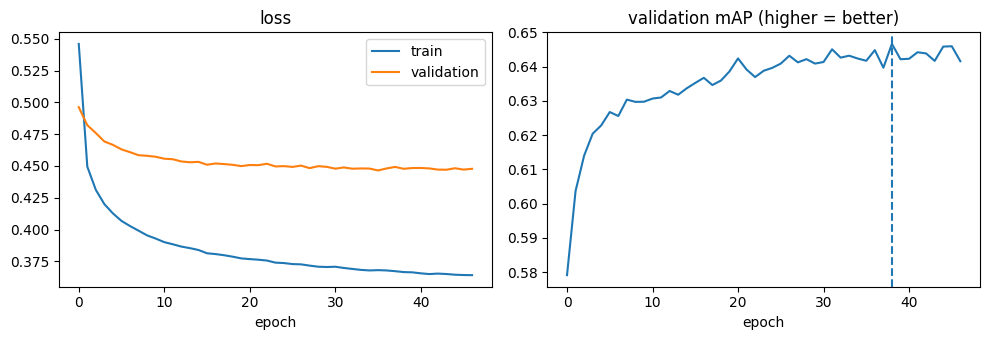

epochs run: 47 | best epoch: 39 | best validation mAP: 0.647


In [ ]:
# ---------------------------------------------------------------
# Cell 12: Train; early stopping on validation mAP, patience 8 (v2: 12)
#   v1 stopped on validation LOSS, which rose from epoch 1 although detection could still improve.
#   v2 stops on validation mean average precision (mAP, how well positives are ranked above negatives).
# ---------------------------------------------------------------
import matplotlib.pyplot as plt
from sklearn.metrics import average_precision_score

def val_map():
    P = model(Xva, training=False).numpy()
    aps = []
    for k in range(len(HEAD)):
        m = Yva[:, k] >= 0
        if (Yva[m, k] == 1).sum() > 0:
            aps.append(average_precision_score(Yva[m, k], P[m, k]))
    return float(np.mean(aps))

class MapStop(keras.callbacks.Callback):
    """Keep the weights with the best validation mAP; stop after 12 epochs without improvement."""
    def __init__(self, patience=12):
        super().__init__(); self.patience, self.best, self.wait, self.hist = patience, -1, 0, []
    def on_epoch_end(self, epoch, logs=None):
        v = val_map(); self.hist.append(v)
        if v > self.best + 1e-4:
            self.best, self.wait, self.best_w, self.best_epoch = v, 0, self.model.get_weights(), epoch + 1
        else:
            self.wait += 1
            if self.wait >= self.patience:
                self.model.stop_training = True
    def on_train_end(self, logs=None):
        self.model.set_weights(self.best_w)

stopper = MapStop(patience=8)
hist = model.fit(Xtr, Ytr, validation_data=(Xva, Yva), epochs=150, batch_size=256, verbose=0, callbacks=[stopper])
fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
ax[0].plot(hist.history['loss'], label='train'); ax[0].plot(hist.history['val_loss'], label='validation'); ax[0].set_title('loss'); ax[0].legend()
ax[1].plot(stopper.hist); ax[1].set_title('validation mAP (higher = better)'); ax[1].axvline(stopper.best_epoch - 1, ls='--')
for a in ax: a.set_xlabel('epoch')
plt.tight_layout(); plt.savefig(f'{OUT}/step5v11_training_curves.png', dpi=150); plt.show()
print(f'epochs run: {len(stopper.hist)} | best epoch: {stopper.best_epoch} | best validation mAP: {stopper.best:.3f}')

In [ ]:
# ---------------------------------------------------------------
# Cell 13: Clip scores for any head model
#   2-window score = best probability that 2 CONSECUTIVE windows both reach (the rule since v3, ≈ 2.4 s of sound)
#   1-window score = best single window (the v7 short-sound rule, ≈ 1.9 s; used only for SHORT sounds)
#   mostly-silent windows = 0 in both
# ---------------------------------------------------------------
def head_clip_scores_both(emb, act, net):
    """Per head sound: (2-window score, 1-window score) of one clip."""
    n = len(emb)
    if n < WIN_F:
        P = net(emb.mean(0, keepdims=True), training=False).numpy()
    else:
        a = act if act.any() else np.ones(n, bool)
        P = net(np.stack([emb[i:i + WIN_F].mean(0) for i in range(n - WIN_F + 1)]), training=False).numpy()
        ok = np.array([a[i:i + WIN_F].sum() >= 2 for i in range(n - WIN_F + 1)])
        if ok.any():
            P[~ok] = 0
    return (np.array([run_score(P[:, k], 2) for k in range(P.shape[1])]),
            np.array([run_score(P[:, k], 1) for k in range(P.shape[1])]))

def head_clip_scores(emb, act, net):
    """2-window score only (used by the FSD50K eval cell)."""
    return head_clip_scores_both(emb, act, net)[0]

SHORT = ['scream']                                                         # sounds allowed to use the short-sound rule

# Expected alerts per folder over the 25 internal sounds: own = 1, others = 0, -1 = not counted
# (another alert is acceptable, or it is the same v2.0 alert: fire_alarm / alarm, crowd / laughter, rain / thunder)
IGNORE = {'fire_alarm': ['alarm'], 'emergency_siren': ['alarm'], 'thunder': ['rain'], 'laughter': ['crowd'],
          'clapping': ['crowd'], 'horn': ['traffic'], 'skid': ['traffic'], 'rooster': ['birds'],
          'alarm': ['fire_alarm'], 'crowd': ['laughter'], 'rain': ['thunder']}
def target_all(sound, f):
    exp = overlap_expected(f) if sound == 'overlap' else {sound}
    y = np.array([1 if s in exp else 0 for s in ALLS])
    for s in IGNORE.get(sound, []):
        y[ALLS.index(s)] = -1
    return y

# The frozen v6b system, for comparison (same code as steps 7 / 9)
model_v6 = keras.models.load_model(f"{OUT}/{CFG6B['model_file']}", compile=False)
model_v10 = keras.models.load_model(f"{OUT}/{CFG10['model_file']}", compile=False)     # compared as v10a
def fire(mode, h, mp):
    return {'head': h, 'mapping': mp, 'head_or_mapping': h or mp, 'head_and_mapping': h and mp}[mode]
def v6b_internal(ms, hs6):
    out = set()
    for s in ALLS:
        t = CFG6B['mapping_thresholds'].get(s)
        mp = s in ms and t is not None and ms[s] >= t
        if s in CFG6B['classes']:
            if fire(CFG6B['mode'][s], hs6[CFG6B['classes'].index(s)] >= CFG6B['thresholds'][s], mp):
                out.add(s)
        elif mp:
            out.add(s)
    return apply_priority(out)
print('ready | short-sound rule allowed for:', SHORT)

ready | short-sound rule allowed for: ['scream']


In [ ]:
# ---------------------------------------------------------------
# Cell 14: Score every tuning clip once
#   set A (old tuning set, same as v6b): our recordings not used in training + test_final round 1
#   round 3: the 104 round-3 clips (never trained on)
# ---------------------------------------------------------------
tune_rows = []
def add(src_name, sound, f, out):
    raw, emb, act = out
    mask = act if act.any() else np.ones(len(raw), bool)
    ms = mapping_scores(raw, mask)
    h2, h1 = head_clip_scores_both(emb, act, model)
    g2, g1 = head_clip_scores_both(emb, act, model_v6)
    s2, s1 = head_clip_scores_both(emb, act, model_v10)
    tune_rows.append(dict(src=src_name, sound=sound, file=f, frames=len(raw), active=int(act.sum()), y=target_all(sound, f),
                          ms=ms, hs=h2, hs1=h1, hs10=s2, hs10_1=s1, hs6=g2, hs6_1=g1, v6b=sorted(to_v2(v6b_internal(ms, g2)))))
for _, r in OURS[OURS.split != 'train'].iterrows():
    add('ours', r.sound, r.file, OUR_OUT[(r.sound, r.file)])
for _, r in TF.iterrows():
    add('test_final', r.sound, r.file, TF_OUT[(r.sound, r.file)])
for _, r in R3.iterrows():
    add('round3', r.sound, r.file, R3_OUT[(r.sound, r.file)])
TU = pd.DataFrame(tune_rows)
N = len(TU)
Y = np.stack(TU.y.values)                                                  # clips x 25 internal sounds (1 / 0 / -1)
V2F = np.array(['other' if s == 'other' else TO_V2.get(s) for s in TU.sound], dtype=object)   # folder as a v2.0 sound (None = removed / overlap)
A = (TU.src != 'round3').values                                            # old tuning set
R3m = (TU.src == 'round3').values                                          # round-3 clips
ALL = np.ones(N, bool)
print('tuning clips:', N, '| old set A:', A.sum(), '| round 3:', R3m.sum())

tuning clips: 380 | old set A: 286 | round 3: 94


In [ ]:
# ---------------------------------------------------------------
# Cell 15: Scream scores (v6 / v10 / v11) and ALARM scores of every alarm tuning clip (all fire alarms since 10 Nov)
#   For every scream clip: length, active frames, and the head scream score with 2 windows vs 1 window.
#   If the missed screams have a clearly higher 1-window score, the 2-window rule was the reason.
# ---------------------------------------------------------------
k6, k7 = CFG6B['classes'].index('scream'), HEAD.index('scream')
t6 = CFG6B['thresholds']['scream']
rows = []
for i in np.where(TU.sound == 'scream')[0]:
    r = TU.iloc[i]
    rows.append(dict(src=r.src, file=r.file, seconds=round(r.frames * 0.48, 1), active_frames=r.active,
                     v6_2win=r.hs6[k6], v6_1win=r.hs6_1[k6], v6b_threshold=t6, v6b_alert='scream' in r.v6b,
                     v10_2win=r.hs10[k7], v10_1win=r.hs10_1[k7], v11_2win=r.hs[k7], v11_1win=r.hs1[k7]))
SC = pd.DataFrame(rows)
display(SC.style.format({c: '{:.3f}' for c in ['v6_2win', 'v6_1win', 'v6b_threshold', 'v10_2win', 'v10_1win', 'v11_2win', 'v11_1win']}))
r3 = SC[SC.src == 'round3']
print(f"round 3 screams: v6 2-window >= threshold {int((r3.v6_2win >= t6).sum())}/{len(r3)} | v6 1-window >= threshold {int((r3.v6_1win >= t6).sum())}/{len(r3)}")
SC.to_csv(f'{OUT}/step5v11_scream_check.csv', index=False, encoding='utf-8-sig')

# --- ALARM check. Head alarm score (2 windows) of every alarm / fire-alarm tuning clip, v6 vs v10 vs v11.
#     Since 10 Nov the alarm folders hold only fire alarms (Saudi alerts moved to data/alarm_excluded).
if 'alarm' in HEAD and 'alarm' in CFG6B['classes']:
    a6, a9 = CFG6B['classes'].index('alarm'), HEAD.index('alarm')
    arows = []
    for i in np.where(TU.sound.isin(['alarm', 'fire_alarm']))[0]:
        r = TU.iloc[i]
        arows.append(dict(src=r.src, sound=r.sound, file=r.file, seconds=round(r.frames * 0.48, 1),
                          v6_2win=r.hs6[a6], v6b_threshold=CFG6B['thresholds']['alarm'], v6b_alerts=', '.join(r.v6b),
                          v10_2win=r.hs10[a9], v11_2win=r.hs[a9]))
    AC = pd.DataFrame(arows)
    display(AC.style.format({c: '{:.3f}' for c in ['v6_2win', 'v6b_threshold', 'v10_2win', 'v11_2win']}))
    r3a = AC[AC.src == 'round3']
    print('round-3 alarm scores (2 windows):', ' | '.join(f"{f[:20]}: v10 {a:.2f} -> v11 {b:.2f}" for f, a, b in zip(r3a.file, r3a.v10_2win, r3a.v11_2win)))
    AC.to_csv(f'{OUT}/step5v11_alarm_check.csv', index=False, encoding='utf-8-sig')
else:
    print('alarm is not a head sound in this config: alarm check skipped')

,src,file,seconds,active_frames,v6_2win,v6_1win,v6b_threshold,v6b_alert,v10_2win,v10_1win,v11_2win,v11_1win
0,ours,316648__bevibeldesign__yell-kid-male-help-help.aiff,1.900000,3,0.931,0.972,0.650,True,0.940,0.977,0.949,0.979
1,ours,845164__danjfilms__woman-screaming.wav,3.400000,7,0.971,0.988,0.650,True,0.979,0.983,0.982,0.983
2,ours,850492__johntrap__screamteenagequeens-audio2601.wav,71.500000,112,0.986,0.993,0.650,True,0.986,0.991,0.988,0.993
3,ours,850699__ienba__female-scream.wav,5.800000,12,0.894,0.901,0.650,True,0.935,0.943,0.937,0.937
4,ours,862439__vsessa__kid-loud-scream-2.wav,2.900000,6,0.961,0.969,0.650,True,0.945,0.959,0.937,0.960
5,ours,872929__riippumattog__weak-scream.wav,3.800000,8,0.680,0.800,0.650,True,0.780,0.846,0.815,0.876
6,ours,873718__vanengelen__voxscrm_loud-scream-male-medium-distance-in-forest-lcr.wav,43.700000,49,0.970,0.984,0.650,True,0.984,0.993,0.986,0.994
7,test_final,178410__jorickhoofd__screams-of-frustration.wav,3.400000,7,0.958,0.977,0.650,True,0.975,0.982,0.975,0.981
8,test_final,243380__johnsonbrandediting__human-male-scream-4.mp3,2.400000,4,0.907,0.919,0.650,True,0.963,0.974,0.968,0.977
9,test_final,339309__kalibrk__jirkascream.mp3,1.000000,2,0.889,0.889,0.650,True,0.924,0.924,0.915,0.915


round 3 screams: v6 2-window >= threshold 1/5 | v6 1-window >= threshold 1/5


,src,sound,file,seconds,v6_2win,v6b_threshold,v6b_alerts,v10_2win,v11_2win
0,ours,fire_alarm,170944__jan18101997__smoke_alarm_piep_piep.wav,6.700000,0.879,0.825,"alarm, washing_machine",0.932,0.944
1,ours,fire_alarm,369848__splicesound__smoke-detector-alarm-close-perspective.wav,15.800000,0.919,0.825,alarm,0.962,0.975
2,ours,fire_alarm,516057__engineer_815__firealarm.wav,27.400000,0.971,0.825,alarm,0.976,0.978
3,ours,fire_alarm,530094__garuda1982__smoke-detector-fire-alarm-sound-effect.wav,19.700000,0.740,0.825,"alarm, washing_machine",0.922,0.937
4,ours,fire_alarm,557484__liftpizzas__loud-smoke-alarm-unplug.wav,18.200000,0.911,0.825,alarm,0.963,0.957
5,ours,fire_alarm,666761__opalmirage__smoke-alarm.wav,24.500000,0.936,0.825,"alarm, washing_machine",0.968,0.964
6,ours,fire_alarm,680073__jess90__smoke-alarm.wav,32.200000,0.912,0.825,alarm,0.966,0.972
7,ours,fire_alarm,856776__loganzsound__first-alert-smoke-detector-1m-away.wav,11.500000,0.898,0.825,"alarm, bell",0.961,0.961
8,round3,alarm,alarm_LM_r3_01_yt.m4a,13.000000,0.890,0.825,"alarm, washing_machine",0.967,0.955
9,round3,alarm,alarm_LM_r3_02_yt.m4a,13.400000,0.545,0.825,,0.517,0.436


round-3 alarm scores (2 windows): alarm_LM_r3_01_yt.m4: v10 0.97 -> v11 0.96 | alarm_LM_r3_02_yt.m4: v10 0.52 -> v11 0.44 | alarm_LM_r3_03_yt.m4: v10 0.90 -> v11 0.91


In [ ]:
# ---------------------------------------------------------------
# Cell 16: All options per sound, then choose with SENSITIVITY TIERS (same method as v6b-v10)
#   v11 (RS 10 Nov): birds is NOT re-tuned. It uses YAMNet alone at its labels threshold (0.475, tuned on ESC-50).
#   Reason: v6b raised it to 0.925 on 4 clips; on round 4 YAMNet alone found 4/5 birds and v10 only 2/5 (log 6.20).
#   head sound    : head(t) | mapping | head OR mapping | head AND mapping     (mapping at the labels threshold)
#   SHORT sound   : also 'head_short'(t) = ONE window above t is enough (short-sound rule)
#   untrained one : mapping with a re-tuned threshold t
#   A sound takes its highest-recall option whose false-alarm rate (on tuning clips without it) is within its tier allowance.
#   v7: critical allowance tried up to 12% (v6b: up to 8%), and total false alarms on 'other' <= 20% (= the NFR; v6b: 25%).
#   Detection per tier is measured with the v11 names (16 sounds: v2.0 without phone_tone), like the test rounds.
# ---------------------------------------------------------------
grid = np.round(np.arange(0.05, 0.976, 0.025), 3)
MS = {s: np.array([d[s] for d in TU.ms]) for s in MAPPED}
HS, HS1 = np.stack(TU.hs.values), np.stack(TU.hs1.values)                 # v11 scores
HS10, HS10_1 = np.stack(TU.hs10.values), np.stack(TU.hs10_1.values)          # v10 scores (the round-4 model)

FIXED_MAP = {'birds': THR['birds']}                                        # RS 10 Nov: birds = YAMNet alone at 0.475
assert abs(FIXED_MAP['birds'] - 0.475) < 1e-9, FIXED_MAP
def make_options(allow_short, HS=HS, HS1=HS1):
    """sound -> list of (mode, head_t, map_t, prediction over all N tuning clips)."""
    opts = {}
    for s in ALLS:
        o = []
        if s in HEAD:
            k = HEAD.index(s)
            mp = MS[s] >= THR[s] if s in MAPPED else None
            for t in grid:
                h = HS[:, k] >= t
                o.append(('head', t, None, h))
                if mp is not None:
                    o += [('head_or_mapping', t, THR[s], h | mp), ('head_and_mapping', t, THR[s], h & mp)]
                if allow_short and s in SHORT:
                    o.append(('head_short', t, None, HS1[:, k] >= t))
            if mp is not None:
                o.append(('mapping', None, THR[s], mp))
        elif s in FIXED_MAP:                                               # v11: fixed threshold, no re-tuning
            o.append(('mapping', None, FIXED_MAP[s], MS[s] >= FIXED_MAP[s]))
        else:
            for t in sorted(set(grid) | {THR[s]}):
                o.append(('mapping', None, float(t), MS[s] >= t))
        opts[s] = o
    return opts

def choose(caps, rows, opts):
    """caps: allowance per sound; rows: tuning clips used. Highest recall within the allowance (ties: closest to the labels threshold); else lowest FA."""
    pick = {}
    for j, s in enumerate(ALLS):
        pos, neg = (Y[:, j] == 1) & rows, (Y[:, j] == 0) & rows
        sc = [(o, (o[3] & pos).sum() / max(pos.sum(), 1), (o[3] & neg).sum() / max(neg.sum(), 1)) for o in opts[s]]
        ok = [x for x in sc if x[2] <= caps[s] + 1e-9]
        ref = THR.get(s, 0.5)
        best = max(ok, key=lambda x: (x[1], -x[2], -abs((x[0][2] or ref) - ref))) if ok else min(sc, key=lambda x: (x[2], -x[1]))
        pick[s] = dict(mode=best[0][0], head_t=best[0][1], map_t=best[0][2], pred=best[0][3], recall=best[1], fa=best[2])
    return pick

def alerts_v2(pick):
    """v2.0 alerts of every tuning clip: internal choices -> v1.9 priority -> v2.0 output layer."""
    F = np.stack([pick[s]['pred'] for s in ALLS], axis=1)
    return [sorted(to_v2(apply_priority({s for j, s in enumerate(ALLS) if F[i, j]}))) for i in range(N)]

CRIT2, IMP2 = ['emergency_siren', 'alarm'], ['knock', 'bell', 'scream']          # v2.0 tiers (same as round 3)
REST2 = [s for s in R1V2 if s not in CRIT2 + IMP2]
def detection(alerts, rows, sounds):
    """Mean over v2.0 sounds (that have clips in rows) of the share of clips with the right alert."""
    d = [np.mean([s in alerts[i] for i in np.where(rows & (V2F == s))[0]]) for s in sounds if (rows & (V2F == s)).any()]
    return float(np.mean(d)) if d else np.nan
def false_alarm_other(alerts, rows):
    return float(np.mean([len(alerts[i]) > 0 for i in np.where(rows & (V2F == 'other'))[0]]))
def summary(alerts, rows):
    return dict(false_alarm_other=false_alarm_other(alerts, rows), critical_det=detection(alerts, rows, CRIT2),
                important_det=detection(alerts, rows, IMP2), rest_det=detection(alerts, rows, REST2), all_det=detection(alerts, rows, R1V2))

CRIT_I = ['emergency_siren', 'fire_alarm', 'alarm']                         # internal critical (explosion is removed in v2.0)
IMP_I = ['knock', 'bell', 'scream']
def tier_caps(c, r):
    return {s: (c if s in CRIT_I else 0.75 * c if s in IMP_I else r) for s in ALLS}

MAX_FA_OTHER = 0.20
def select(rows, opts, name):
    """Try the tier allowances; keep the best critical, then important, then all detection with false alarms on other <= 20%."""
    trials = []
    for c in [0.04, 0.06, 0.08, 0.10, 0.12]:
        for r in [0.01, 0.015, 0.02, 0.03]:
            trials.append(dict(critical=c, important=0.75 * c, rest=r, **summary(alerts_v2(choose(tier_caps(c, r), rows, opts)), rows)))
    TR = pd.DataFrame(trials)
    ok = TR[TR.false_alarm_other <= MAX_FA_OTHER]
    if len(ok):
        best = ok.sort_values(['critical_det', 'important_det', 'all_det', 'false_alarm_other'], ascending=[False, False, False, True]).iloc[0]
    else:
        print(f'{name}: no combination keeps false alarms on other <= 20%; taking the best detection minus false alarms')
        best = TR.assign(b=TR.all_det - TR.false_alarm_other).sort_values('b').iloc[-1]
    c, r = float(best.critical), float(best.rest)
    print(f'{name:22s} chosen allowance: critical {c:.0%} | important {0.75 * c:.1%} | rest {r:.1%}')
    return choose(tier_caps(c, r), rows, opts), TR, (c, r)

OPT_FULL, OPT_V10 = make_options(True), make_options(True, HS10, HS10_1)
PICK_A10, TR_A10, CAP_A10 = select(A, OPT_V10, 'v10a (v10 model)')            # tuned on old set A only (with the v11 rules)
PICK_A, TR_A, CAP_A = select(A, OPT_FULL, 'v11a (v11 model)')               # tuned on old set A only
PICK_F, TR_F, CAP_F = select(ALL, OPT_FULL, 'v11 (final)')                 # tuned on A + round 3
fmt = {c: '{:.0%}' for c in ['critical_det', 'important_det', 'rest_det', 'all_det', 'false_alarm_other']} | {c: '{:.1%}' for c in ['critical', 'important', 'rest']}
print('\nv11 final: every allowance tried (tuning set A + round 3)')
display(TR_F.style.format(fmt))

In [ ]:
# ---------------------------------------------------------------
# Cell 17: The final v11 choices per sound (tuning set A + round 3)
# ---------------------------------------------------------------
TIER_I = lambda s: 'critical' if s in CRIT_I else 'important' if s in IMP_I else 'rest'
CH = pd.DataFrame([dict(sound=s, v2=TO_V2.get(s, 'removed'), tier=TIER_I(s), trained=s in HEAD, mode=p['mode'],
                        head_threshold=p['head_t'], map_threshold=p['map_t'], v6b_mode=CFG6B['mode'].get(s),
                        positives=int(((Y[:, j] == 1)).sum()), recall=p['recall'], false_alarm=p['fa'])
                   for j, (s, p) in enumerate(PICK_F.items())])
display(CH.style.format({'recall': '{:.0%}', 'false_alarm': '{:.1%}', 'head_threshold': '{:.3f}', 'map_threshold': '{:.3f}'}, na_rep='-'))
CH.to_csv(f'{OUT}/step5v11_choices.csv', index=False, encoding='utf-8-sig')
pd.concat([TR_A10.assign(version='v10a'), TR_A.assign(version='v11a'), TR_F.assign(version='v11')]).to_csv(
    f'{OUT}/step5v11_tier_trials.csv', index=False, encoding='utf-8-sig')

In [ ]:
# ---------------------------------------------------------------
# Cell 18: THE CHECK: v6b vs v10a vs v11a on the ROUND-3 clips (v11 names: 16 sounds, no phone_tone)
#   All three were tuned on the old set A only (without alarm_LM_01_yt), and none was trained on round 3 -> a fair
#   comparison between them. Not a new test (we already saw round 3): the honest number comes from round 5.
#   v6b / v10a / v11a all use the v11 output layer here (no phone_tone, birds at 0.475 for v10a / v11a).
# ---------------------------------------------------------------
from collections import Counter
SYS_R3 = {'v6b': list(TU.v6b), 'v10a': alerts_v2(PICK_A10), 'v11a': alerts_v2(PICK_A)}
ALLOWED_EXTRA = {'rooster': {'birds'}}                                     # a rooster is also a bird
def per_sound(systems, rows):
    out = []
    for s in R1V2:
        ii = np.where(rows & (V2F == s))[0]
        if not len(ii):
            continue
        r = dict(tier='critical' if s in CRIT2 else 'important' if s in IMP2 else 'rest', sound=s, clips=len(ii))
        for k, al in systems.items():
            r[f'{k}_det'] = np.mean([s in al[i] for i in ii])
            r[f'{k}_wrong'] = np.mean([any(x != s and x not in ALLOWED_EXTRA.get(s, set()) for x in al[i]) for i in ii])
        out.append(r)
    return pd.DataFrame(out)
R3RES = per_sound(SYS_R3, R3m)
display(R3RES.style.format({c: '{:.0%}' for c in R3RES.columns if c.endswith(('_det', '_wrong'))}))
SUM_R3 = {k: summary(al, R3m) for k, al in SYS_R3.items()}
for k, v in SUM_R3.items():
    print(f"{k:13s} | false alarms on other ({int((R3m & (V2F == 'other')).sum())}): {v['false_alarm_other']:.0%} | critical {v['critical_det']:.0%}, "
          f"important {v['important_det']:.0%}, rest {v['rest_det']:.0%}, all {v['all_det']:.0%} |",
          'alerts on other:', Counter(x for i in np.where(R3m & (V2F == 'other'))[0] for x in SYS_R3[k][i]).most_common(3))
print('\nFor information only, the NFR on round 3 (round 3 is not a new test):')
for k, v in SUM_R3.items():
    n_ok = sum([v['critical_det'] >= 0.80, v['important_det'] >= 0.75, v['all_det'] >= 0.70, v['false_alarm_other'] <= 0.20])
    print(f'  {k:13s} {n_ok} of 4')
R3RES.to_csv(f'{OUT}/step5v11_round3_check.csv', index=False, encoding='utf-8-sig')

# For information only (option discussed with RS, 8 Nov): 'any emergency alert'. A siren or alarm clip counts as caught
# if EITHER emergency alert fires. The official numbers above keep siren and alarm as two separate sounds.
EMERG = {'emergency_siren', 'alarm'}
def any_emergency(alerts, rows):
    """(caught, clips) over the siren + alarm folders, counting either emergency alert as right."""
    ii = np.where(rows & np.isin(V2F, list(EMERG)))[0]
    return sum(bool(EMERG & set(alerts[i])) for i in ii), len(ii)
print('\nFor information only: any emergency alert on the siren + alarm clips of round 3')
for k, al in SYS_R3.items():
    c, n = any_emergency(al, R3m)
    print(f'  {k:5s} {c}/{n} = {c / n:.0%}')

In [ ]:
# ---------------------------------------------------------------
# Cell 19: Final v11 vs v6b on the whole tuning set (A + round 3)
#   ⚠️ OPTIMISTIC for v11: its choices were made on these clips. Use it to see what changed, not as a result.
# ---------------------------------------------------------------
SYS_ALL = {'v6b': list(TU.v6b), 'v11': alerts_v2(PICK_F)}
ALLRES = per_sound(SYS_ALL, ALL)
display(ALLRES.style.format({c: '{:.0%}' for c in ALLRES.columns if c.endswith(('_det', '_wrong'))}))
SUM_ALL = {k: summary(al, ALL) for k, al in SYS_ALL.items()}
for k, v in SUM_ALL.items():
    print(f"{k:4s} | false alarms on other ({int((V2F == 'other').sum())}): {v['false_alarm_other']:.0%} | critical {v['critical_det']:.0%}, "
          f"important {v['important_det']:.0%}, rest {v['rest_det']:.0%}, all {v['all_det']:.0%}")
print('\nWeak sounds (round-3 clips, final v11 = tuned on them, optimistic):')
SYS_R3F = {'v6b': list(TU.v6b), 'v10a': SYS_R3['v10a'], 'v11a': SYS_R3['v11a'], 'v11': SYS_ALL['v11']}
for s in ['scream', 'alarm', 'rain', 'dog', 'birds', 'washing_machine']:
    ii = np.where(R3m & (V2F == s))[0]
    print(f'  {s:11s}', ' | '.join(f"{k} {sum(s in al[i] for i in ii)}/{len(ii)}" for k, al in SYS_R3F.items()))
ALLRES.to_csv(f'{OUT}/step5v11_tuning_results.csv', index=False, encoding='utf-8-sig')
TU[['src', 'sound', 'file']].assign(v6b=[', '.join(a) for a in SYS_ALL['v6b']], v11=[', '.join(a) for a in SYS_ALL['v11']]).to_csv(
    f'{OUT}/step5v11_tuning_per_file.csv', index=False, encoding='utf-8-sig')
print('\nFor information only: any emergency alert (siren + alarm clips)')
for k, al in SYS_R3F.items():
    c, n = any_emergency(al, R3m); c2, n2 = any_emergency(al, ALL)
    print(f'  {k:5s} round 3: {c}/{n} = {c / n:.0%} | all tuning clips: {c2}/{n2} = {c2 / n2:.0%}')

In [ ]:
# ---------------------------------------------------------------
# Cell 20: FSD50K eval clips, head alone at the chosen thresholds (information only: different kind of audio)
# ---------------------------------------------------------------
E = SEL[SEL.part == 'eval']
EH = np.stack([head_clip_scores(FSD_OUT[f][1], FSD_OUT[f][2], model) for f in E.fname])
EY = np.stack(E.y.values)
rows = []
for k, s in enumerate(HEAD):
    t = PICK_F[s]['head_t'] if PICK_F[s]['head_t'] is not None else 0.5
    m = EY[:, k] >= 0; pred = EH[:, k] >= t; y = EY[:, k]
    tp = (pred & (y == 1) & m).sum(); fp = (pred & (y == 0) & m).sum()
    rows.append(dict(sound=s, threshold=t, positives=int((y == 1).sum()), recall=tp / max((y == 1).sum(), 1),
                     precision=tp / max(tp + fp, 1), false_alarm_on_negatives=fp / max(((y == 0) & m).sum(), 1)))
FE = pd.DataFrame(rows)
display(FE.style.format({c: '{:.0%}' for c in ['recall', 'precision', 'false_alarm_on_negatives']}))
FE.to_csv(f'{OUT}/step5v11_fsd_eval.csv', index=False, encoding='utf-8-sig')

In [ ]:
# ---------------------------------------------------------------
# Cell 21: Save model v11 + its decision config, and update the list of FSD50K clips used in training
#   The v6b-v10 files are NOT changed. v11 becomes the system for round 5 only if the team chooses it (Cell 18).
#   New mode 'head_short' (scream): the head fires if ONE window is above the threshold (instead of 2 consecutive).
# ---------------------------------------------------------------
model.save(f'{OUT}/hesak_head_v11.keras')
num = lambda x: None if x is None else float(x)
cfg = dict(version='head_v11', model_file='hesak_head_v11.keras', labels_version=L['version'], output_labels_version=L20['version'],
           classes=HEAD, mode={s: PICK_F[s]['mode'] for s in ALLS},
           output_layer=dict(base='hesak_labels.json v2.0', removed_sounds=sorted(REMOVED_V11), shown_sounds=R1V2,
                             note='RS 10 Nov: phone_tone is computed inside the head but never shown'),
           fixed_mapping_thresholds=FIXED_MAP,
           thresholds={s: num(PICK_F[s]['head_t']) for s in HEAD},
           mapping_thresholds={s: num(PICK_F[s]['map_t']) for s in MAPPED},
           short_rule=dict(sounds=SHORT, rule="mode 'head_short': the head fires if ONE 3-frame window is above the threshold"),
           tiers=dict(critical=CRIT_I, important=IMP_I, rest=[s for s in ALLS if s not in CRIT_I + IMP_I]),
           false_alarm_allowance=dict(critical=CAP_F[0], important=0.75 * CAP_F[0], rest=CAP_F[1]), max_false_alarm_other=MAX_FA_OTHER,
           tuning_set='our recordings not used in training (without alarm_LM_01_yt: same source as a train_extra clip) + test_final round 1 + test_round3 (104 clips)',
           extra_training=f'test_round2 + data/train_extra (scream, alarm = 27 fire alarms, rain = 5 round-4 copies + new rain-only clips: {EX.sound.value_counts().to_dict()}), all repeated x3; alarm = FIRE ALARM ONLY (RS 10 Nov, 23 Saudi clips moved to data/alarm_excluded); v2.0 merges used as targets (fire_alarm -> alarm, thunder -> rain)',
           round3_check=dict(note='v10a / v11a = v10 / v11 model tuned on the old set only; fair vs v6b on round 3, but round 3 is not a new test',
                             summary=SUM_R3, allowance_v10a=CAP_A10, allowance_v11a=CAP_A,
                             any_emergency_info={k: any_emergency(al, R3m) for k, al in SYS_R3.items()}),
           window=dict(frames=WIN_F, rule='mean of 3 consecutive YAMNet embeddings; mostly-silent windows = 0'),
           clip_rule="head fires if 2 consecutive windows are above its threshold (mode 'head_short': 1 window)",
           hybrid_rule='per sound: head / head_short / mapping / head_or_mapping / head_and_mapping, then v1.9 priority, then the v2.0 output layer',
           train=dict(fsd_cap=CAP, fsd_cap_weak=CAP_WEAK, weak=sorted(WEAK), fsd_neg=NEG, seed=SEED, real_repeat=REAL_REPEAT,
                      best_epoch=stopper.best_epoch, best_val_map=stopper.best, input_dropout=0.2, dropout=0.5, l2=1e-4, lr=3e-4,
                      pos_weight_cap=5, label_smoothing=LS, patience=8),
           fsd50k_repo=REPO)
json.dump(cfg, open(f'{OUT}/hesak_head_v11_config.json', 'w'), indent=2)

SEL[['fname', 'part', 'labels']].to_csv(f'{OUT}/step5v11_fsd50k_clips_used.csv', index=False)
old = pd.read_csv(f'{OUT}/step5_fsd50k_clips_used.csv', dtype={'fname': str})
both = pd.concat([old, SEL[['fname', 'part', 'labels']].astype({'fname': str})]).drop_duplicates('fname')
both.to_csv(f'{OUT}/step5_fsd50k_clips_used.csv', index=False)
print(f'Saved: hesak_head_v11.keras, hesak_head_v11_config.json | FSD50K clips used (all versions): {len(both)}')

## How to read the results
- **Cell 5c:** extra clips: scream, alarm (27 fire alarms), rain (5 round-4 copies + new rain-only clips). No Saudi alert left.
- **Cell 12:** training curves.
- **Cell 15:** scream and alarm scores per clip (v6 / v10 / v11).
- **Cell 18 (the one to decide on):** v6b vs v10a vs v11a on the round-3 clips (16 sounds), per sound and per tier, false alarms on `other`.
- **Cell 19:** final v11 vs v6b on all tuning clips (optimistic).
- ⚠️ No round-3 or tuning clip is rain WITHOUT thunder, so the rain-only change can only be measured in round 5.

**Next:** the team decides if v11 goes to round 5, fixes the round-5 NFR, then collects round 5 (16 sounds x 5 + 15 `other`, all new) and runs it once.
Please send the downloaded `.ipynb`. **The results discussion in the report is written by the team.**

In [1]:
# Print the TensorFlow and Keras versions used in this run
import tensorflow as tf
import keras

print("TensorFlow version:", tf.__version__)
print("Keras version:", keras.__version__)

TensorFlow version: 2.21.0
Keras version: 3.13.2
